<a href="https://colab.research.google.com/github/janarthmanoharan7/Brooklyn-Library-Set-Analysis/blob/main/brooklyn_library_set_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

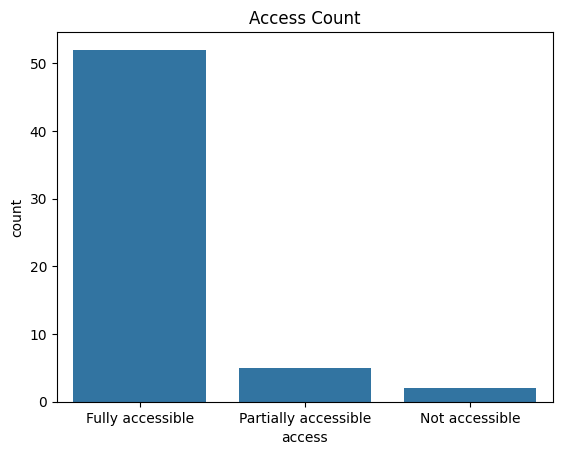

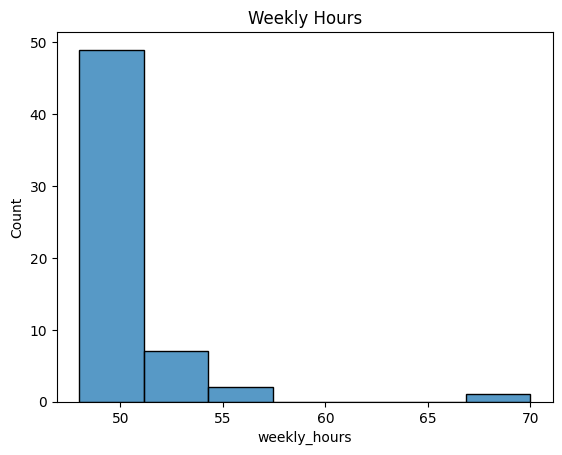

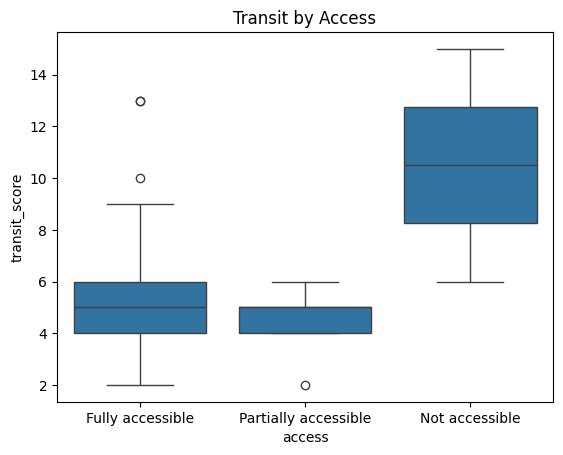

In [ ]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns, re
from datetime import datetime as dt, date

df = pd.read_csv('/BPL_Locations.csv')
df.columns = df.columns.str.lower().str.replace(' ', '_').str.replace(r'\W', '', regex=True)
df.fillna({'access':'Unknown', 'subway':'', 'tags':'', 'bus':''}, inplace=True)
df[['latitude', 'longitude']] = df['position'].str.split(',', expand=True).astype(float)

def parse(x):
 t=re.findall(r'(\d{1,2}:\d{2}(?:am|pm))',str(x))
 return pd.Series([pd.to_datetime(t[0]).time() if t else None,
                   pd.to_datetime(t[-1]).time() if t else None])
for d in ['monday','tuesday','wednesday','thursday','friday','saturday','sunday']:
 df[[f'{d}_open',f'{d}_close']] = df[d].apply(parse)

sns.countplot(x='access', data=df); plt.title('Access Count'); plt.show()

df['weekly_hours'] = df.apply(lambda r: sum(
 ((dt.combine(date.min, r[f'{d}_close']) - dt.combine(date.min, r[f'{d}_open'])).seconds
 if pd.notna(r[f'{d}_open']) else 0) for d in ['monday','tuesday','wednesday','thursday','friday','saturday','sunday']
)/3600, axis=1)

sns.histplot(df['weekly_hours']); plt.title('Weekly Hours'); plt.show()

df['num_bus_routes'] = df['bus'].str.split(';').apply(lambda x: len([i for i in x if i]))
df['num_subway_lines'] = df['subway'].str.split(';').apply(lambda x: len([i for i in x if i]))
df['transit_score'] = df['num_bus_routes'] + df['num_subway_lines']

sns.boxplot(x='access', y='transit_score', data=df); plt.title('Transit by Access'); plt.show()
